In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define project directories
DATA_DIR = Path("../data/raw")
REPORT_DIR = Path("../reports")

REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Load datasets
train = pd.read_csv(DATA_DIR / "train.csv")
customer_demographics = pd.read_csv(
    DATA_DIR / "customer_demographics.csv"
)
coupon_item_mapping = pd.read_csv(
    DATA_DIR / "coupon_item_mapping.csv"
)
item_data = pd.read_csv(DATA_DIR / "item_data.csv")

# Display dataset shapes
print("Training dataset:", train.shape)
print("Customer demographics:", customer_demographics.shape)
print("Coupon-item mapping:", coupon_item_mapping.shape)
print("Item data:", item_data.shape)

Training dataset: (78369, 5)
Customer demographics: (760, 7)
Coupon-item mapping: (92663, 2)
Item data: (74066, 4)


In [2]:
# Display the first five customer records
display(customer_demographics.head())

# Inspect column names and data types
print("Customer Demographics Information:")
customer_demographics.info()

# Calculate missing values
print("\nMissing Values:")
display(
    customer_demographics.isnull()
    .sum()
    .to_frame(name="missing_count")
    .assign(
        missing_percentage=lambda df:
        (df["missing_count"] / len(customer_demographics) * 100).round(2)
    )
)

# Analyze customer age ranges
print("\nCustomer Age Range Distribution:")
display(customer_demographics["age_range"].value_counts(dropna=False))

# Analyze marital status
print("\nMarital Status Distribution:")
display(customer_demographics["marital_status"].value_counts(dropna=False))

# Analyze income brackets
print("\nIncome Bracket Distribution:")
display(customer_demographics["income_bracket"].value_counts(dropna=False))

,customer_id,age_range,marital_status,rented,family_size,no_of_children,income_bracket
0,1,70+,Married,0,2,NaN,4
1,6,46-55,Married,0,2,NaN,5
2,7,26-35,NaN,0,3,1,3
3,8,26-35,NaN,0,4,2,6
4,10,46-55,Single,0,1,NaN,5


Customer Demographics Information:
<class 'pandas.DataFrame'>
RangeIndex: 760 entries, 0 to 759
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   customer_id     760 non-null    int64
 1   age_range       760 non-null    str  
 2   marital_status  431 non-null    str  
 3   rented          760 non-null    int64
 4   family_size     760 non-null    str  
 5   no_of_children  222 non-null    str  
 6   income_bracket  760 non-null    int64
dtypes: int64(3), str(4)
memory usage: 49.4 KB

Missing Values:


,missing_count,missing_percentage
customer_id,0,0.00
age_range,0,0.00
marital_status,329,43.29
rented,0,0.00
family_size,0,0.00
no_of_children,538,70.79
income_bracket,0,0.00



Customer Age Range Distribution:


age_range
46-55    271
36-45    187
26-35    130
70+       68
56-70     59
18-25     45
Name: count, dtype: int64


Marital Status Distribution:


marital_status
NaN        329
Married    317
Single     114
Name: count, dtype: int64


Income Bracket Distribution:


income_bracket
5     187
4     165
6      88
3      70
2      68
1      59
8      37
7      32
9      29
12     10
10     10
11      5
Name: count, dtype: int64

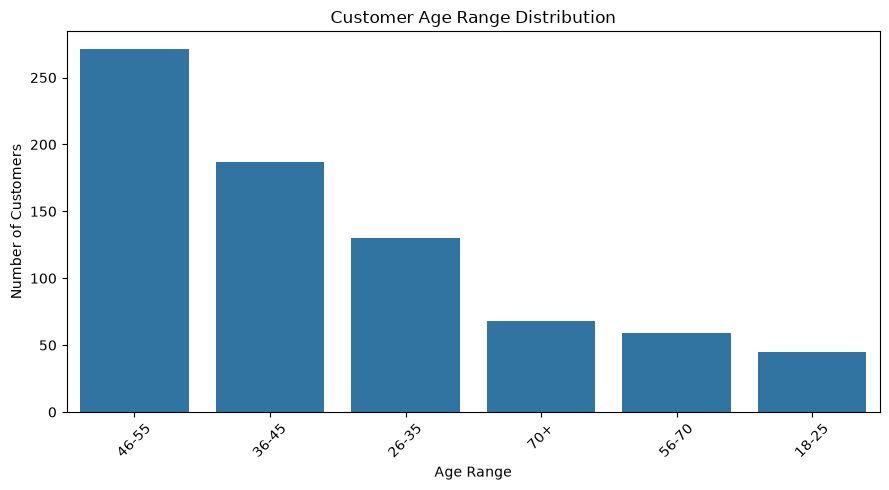

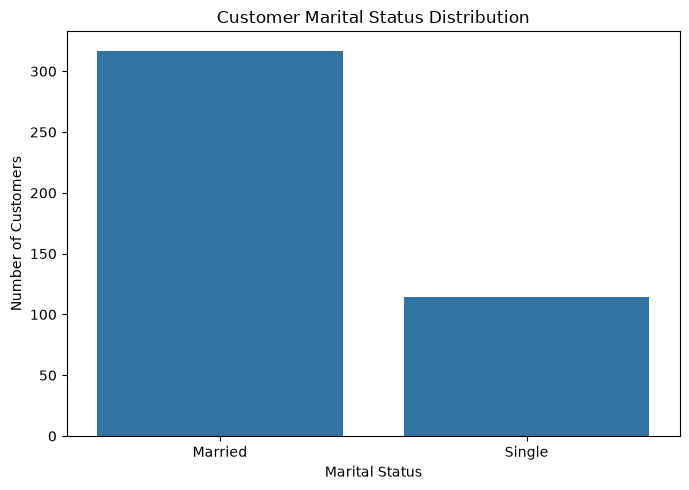

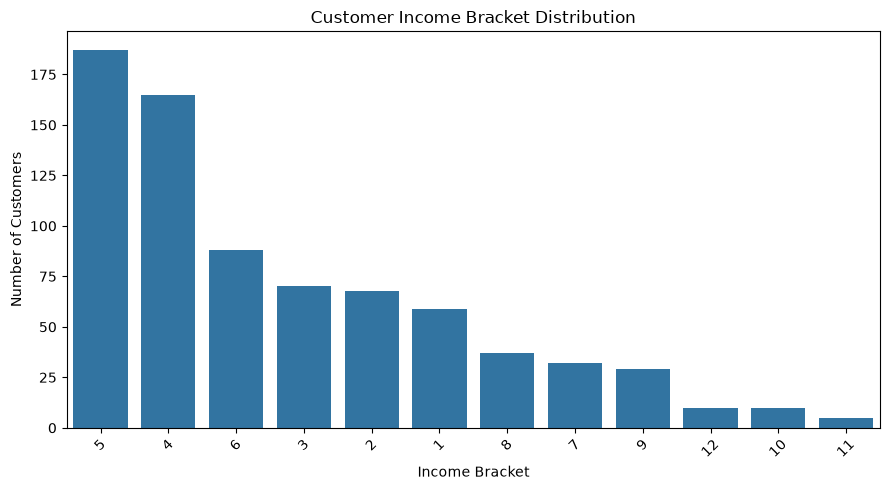

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Customer Age Range Distribution
plt.figure(figsize=(9, 5))
sns.countplot(
    data=customer_demographics,
    x="age_range",
    order=customer_demographics["age_range"].value_counts().index
)
plt.title("Customer Age Range Distribution")
plt.xlabel("Age Range")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 2. Customer Marital Status Distribution
plt.figure(figsize=(7, 5))
sns.countplot(
    data=customer_demographics,
    x="marital_status",
    order=customer_demographics["marital_status"].value_counts().index
)
plt.title("Customer Marital Status Distribution")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# 3. Customer Income Bracket Distribution
plt.figure(figsize=(9, 5))
sns.countplot(
    data=customer_demographics,
    x="income_bracket",
    order=customer_demographics["income_bracket"].value_counts().index
)
plt.title("Customer Income Bracket Distribution")
plt.xlabel("Income Bracket")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [4]:
# Display coupon-item mapping
print("Coupon-Item Mapping:")
display(coupon_item_mapping.head())

# Display item information
print("\nItem Information:")
display(item_data.head())

# Check unique coupon and item counts
print("\nDataset Summary:")
print("Unique coupons:", coupon_item_mapping["coupon_id"].nunique())
print("Unique items in mapping:", coupon_item_mapping["item_id"].nunique())
print("Unique items in item data:", item_data["item_id"].nunique())

# Check missing values
print("\nMissing values in coupon-item mapping:")
display(coupon_item_mapping.isnull().sum())

print("\nMissing values in item data:")
display(item_data.isnull().sum())

# Analyze item categories
print("\nTop 10 Item Categories:")
display(item_data["category"].value_counts().head(10))

# Analyze brand types
print("\nBrand Type Distribution:")
display(item_data["brand_type"].value_counts())

Coupon-Item Mapping:


,coupon_id,item_id
0,105,37
1,107,75
2,494,76
3,522,77
4,518,77



Item Information:


,item_id,brand,brand_type,category
0,1,1,Established,Grocery
1,2,1,Established,Miscellaneous
2,3,56,Local,Bakery
3,4,56,Local,Grocery
4,5,56,Local,Grocery



Dataset Summary:
Unique coupons: 1116
Unique items in mapping: 36289
Unique items in item data: 74066

Missing values in coupon-item mapping:


...

item_id       0
brand         0
brand_type    0
category      0
dtype: int64


Top 10 Item Categories:


category
Grocery                   32448
Pharmaceutical            24471
Natural Products           2533
Dairy, Juices & Snacks     2425
Skin & Hair Care           2244
Meat                       2080
Packaged Meat              1966
Prepared Food              1880
Bakery                     1679
Seafood                     728
Name: count, dtype: int64


Brand Type Distribution:


brand_type
Established    62842
Local          11224
Name: count, dtype: int64

,category,item_count
0,Grocery,32448
1,Pharmaceutical,24471
2,Natural Products,2533
3,"Dairy, Juices & Snacks",2425
4,Skin & Hair Care,2244
5,Meat,2080
6,Packaged Meat,1966
7,Prepared Food,1880
8,Bakery,1679
9,Seafood,728


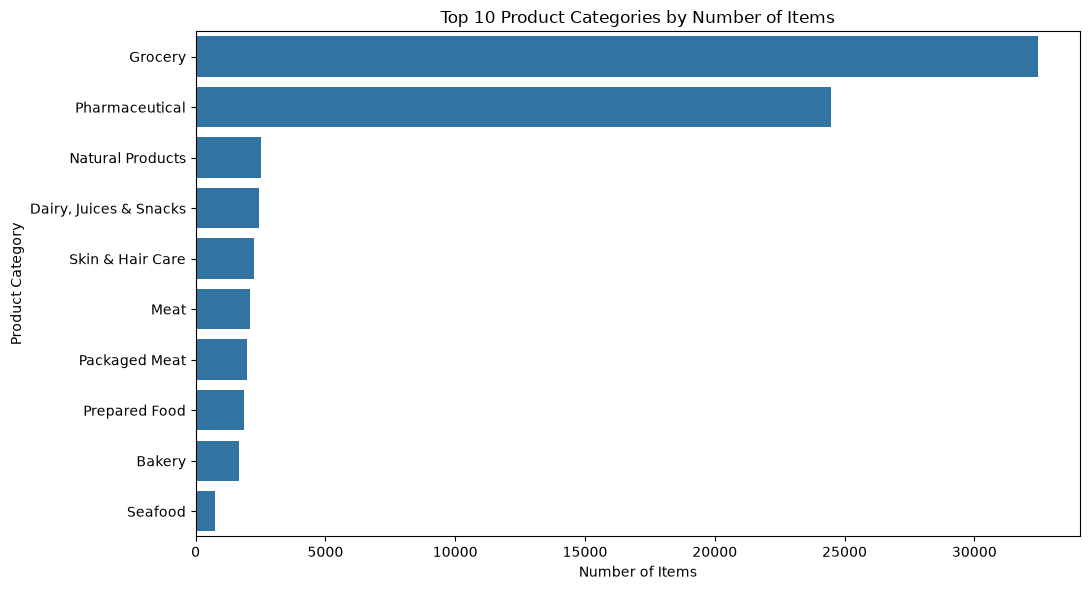

In [5]:
# Count items in each category
category_counts = (
    item_data["category"]
    .value_counts()
    .head(10)
    .reset_index()
)

category_counts.columns = ["category", "item_count"]

display(category_counts)

# Visualize the top 10 categories
plt.figure(figsize=(11, 6))

sns.barplot(
    data=category_counts,
    x="item_count",
    y="category"
)

plt.title("Top 10 Product Categories by Number of Items")
plt.xlabel("Number of Items")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [6]:
# Count items associated with each coupon
coupon_item_counts = (
    coupon_item_mapping
    .groupby("coupon_id")
    .agg(
        total_items=("item_id", "nunique")
    )
    .reset_index()
)

# Sort coupons by the number of associated items
coupon_item_counts = coupon_item_counts.sort_values(
    "total_items", ascending=False
)

print("Top 10 Coupons by Number of Associated Items:")
display(coupon_item_counts.head(10))

# Summary statistics
print("\nCoupon Coverage Statistics:")
display(coupon_item_counts["total_items"].describe())

Top 10 Coupons by Number of Associated Items:


,coupon_id,total_items
31,32,11814
22,23,11813
21,22,4947
30,31,4873
23,24,4394
32,33,4394
7,8,3718
5,6,3713
28,29,3385
19,20,3372



Coupon Coverage Statistics:


count     1116.000000
mean        83.031362
std        633.143339
min          1.000000
25%          5.000000
50%         10.000000
75%         24.000000
max      11814.000000
Name: total_items, dtype: float64

In [7]:
# Merge training data with customer demographics
customer_redemption = train.merge(
    customer_demographics,
    on="customer_id",
    how="left"
)

print("Merged dataset shape:", customer_redemption.shape)

# Check how many records have demographic information
matched = customer_redemption["age_range"].notna().sum()
total = len(customer_redemption)

print("Records with age information:", matched)
print("Records without age information:", total - matched)
print("Percentage with age information:", round(matched / total * 100, 2), "%")

# Calculate redemption rates by age range
age_redemption = (
    customer_redemption
    .groupby("age_range", dropna=False)
    .agg(
        total_records=("redemption_status", "size"),
        total_redemptions=("redemption_status", "sum"),
        redemption_rate=("redemption_status", "mean")
    )
    .reset_index()
)

age_redemption["redemption_rate_pct"] = (
    age_redemption["redemption_rate"] * 100
).round(2)

display(age_redemption.sort_values("redemption_rate_pct", ascending=False))

Merged dataset shape: (78369, 11)
Records with age information: 43661
Records without age information: 34708
Percentage with age information: 55.71 %


,age_range,total_records,total_redemptions,redemption_rate,redemption_rate_pct
3,46-55,15154,219,0.014452,1.45
1,26-35,8024,109,0.013584,1.36
2,36-45,11210,149,0.013292,1.33
4,56-70,3723,49,0.013161,1.32
5,70+,3094,27,0.008727,0.87
0,18-25,2456,15,0.006107,0.61
6,NaN,34708,161,0.004639,0.46


In [8]:
# Calculate redemption rates by marital status
marital_redemption = (
    customer_redemption
    .groupby("marital_status", dropna=False)
    .agg(
        total_records=("redemption_status", "size"),
        total_redemptions=("redemption_status", "sum"),
        redemption_rate=("redemption_status", "mean")
    )
    .reset_index()
)

marital_redemption["redemption_rate_pct"] = (
    marital_redemption["redemption_rate"] * 100
).round(2)

display(
    marital_redemption.sort_values(
        "redemption_rate_pct",
        ascending=False
    )
)

,marital_status,total_records,total_redemptions,redemption_rate,redemption_rate_pct
0,Married,18811,280,0.014885,1.49
1,Single,6583,78,0.011849,1.18
2,NaN,52975,371,0.007003,0.70


In [9]:
# Calculate redemption rates by income bracket
income_redemption = (
    customer_redemption
    .groupby("income_bracket", dropna=False)
    .agg(
        total_records=("redemption_status", "size"),
        total_redemptions=("redemption_status", "sum"),
        redemption_rate=("redemption_status", "mean")
    )
    .reset_index()
)

income_redemption["redemption_rate_pct"] = (
    income_redemption["redemption_rate"] * 100
).round(2)

display(
    income_redemption.sort_values(
        "redemption_rate_pct",
        ascending=False
    )
)

,income_bracket,total_records,total_redemptions,redemption_rate,redemption_rate_pct
5,6.0,4855,98,0.020185,2.02
4,5.0,11037,218,0.019752,1.98
9,10.0,513,8,0.015595,1.56
8,9.0,2019,31,0.015354,1.54
0,1.0,3456,36,0.010417,1.04
7,8.0,2369,23,0.009709,0.97
2,3.0,3882,35,0.009016,0.90
6,7.0,1829,16,0.008748,0.87
3,4.0,8753,76,0.008683,0.87
1,2.0,3892,27,0.006937,0.69


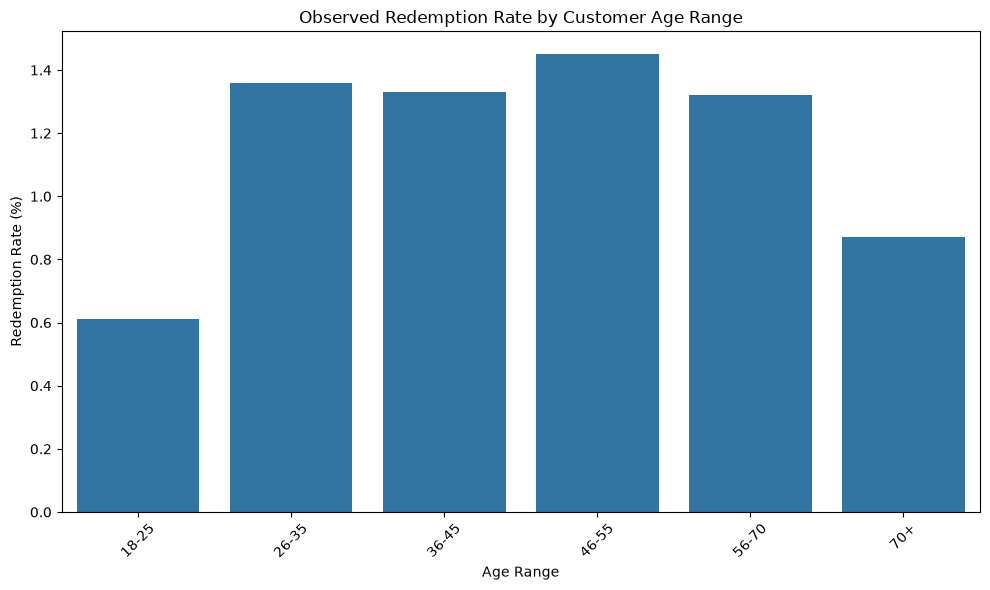

In [10]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_redemption,
    x="age_range",
    y="redemption_rate_pct"
)

plt.title("Observed Redemption Rate by Customer Age Range")
plt.xlabel("Age Range")
plt.ylabel("Redemption Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
# Save customer and coupon analysis results

age_redemption.to_csv(
    REPORT_DIR / "day05_age_redemption.csv",
    index=False
)

marital_redemption.to_csv(
    REPORT_DIR / "day05_marital_redemption.csv",
    index=False
)

income_redemption.to_csv(
    REPORT_DIR / "day05_income_redemption.csv",
    index=False
)

coupon_item_counts.to_csv(
    REPORT_DIR / "day05_coupon_item_counts.csv",
    index=False
)

category_counts.to_csv(
    REPORT_DIR / "day05_category_counts.csv",
    index=False
)

print("Day 5 analysis reports saved successfully!")

print("\nSaved files:")
for file in sorted(REPORT_DIR.glob("day05_*.csv")):
    print(file.name)

Day 5 analysis reports saved successfully!

Saved files:
day05_age_redemption.csv
day05_category_counts.csv
day05_coupon_item_counts.csv
day05_income_redemption.csv
day05_marital_redemption.csv
